# Homework CAPITA SELECTA PU Learning

In [171]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import f1_score, mean_squared_error as mse
from sklearn import svm
from sklearn.linear_model import LogisticRegression

def ignore_warnings():
    import warnings
    warnings.simplefilter(action='ignore', category=FutureWarning)
    warnings.simplefilter(action='ignore', category=Warning)

ignore_warnings()

#from PU_Learning import *
from PU_Learning import *


## First Dataset

#### https://archive.ics.uci.edu/ml/datasets/banknote+authentication

In [172]:
data = pd.read_csv('Dataset1_train.csv')
X1_train= data.iloc[:, :-2].values
y1_train = data.iloc[:, -1].values
s1 = data.iloc[:, -2].values
c1 = Counter(s1)[1]/Counter(y1_train)[1]

data = pd.read_csv('Dataset1_test.csv')
X1_test= data.iloc[:, :-1].values
y1_test = data.iloc[:, -1].values

In [173]:
print(c1)

0.2


### Golden Standard Classifier (first dataset)

In [174]:
# Consider the dataset as fully labeled. Use this as the best case in the comparison.

golden_clf = svm.SVC(kernel='rbf',probability=True,random_state = 331).fit(np.copy(X1_train),np.copy(y1_train))
name = "Golden Standard Classifier:"

y_best_pred = golden_clf.predict(np.copy(X1_test))
y_best_prob = golden_clf.predict_proba(np.copy(X1_test))[:,1]

print(name,"F1 score:", f1_score(y1_test, y_best_pred))

Golden Standard Classifier: F1 score: 0.9917355371900827


### Non-Traditional Classifier (first dataset)

In [175]:
#fit a model on (X, s1) and see the performance. Compare it with the two methods.
non_trad_clf = svm.SVC(kernel='rbf', probability=True, random_state = 331).fit(np.copy(X1_train),np.copy(s1))
name = "Non-Traditional Classifier"

y_pred = non_trad_clf.predict(np.copy(X1_test))
y_pred_prob = non_trad_clf.predict_proba(np.copy(X1_test))[:,1]
print(name,"F1 score:", f1_score(y1_test, y_pred))
print(name,"MSE score:", mse(y_best_prob, y_pred_prob))

Non-Traditional Classifier F1 score: 0.0
Non-Traditional Classifier MSE score: 0.3575893835019963


### Spy Expectation Maximization S-EM (first dataset)

In [176]:
from sklearn.naive_bayes import GaussianNB
pu_classifier = SEM(tol = 1.0e-10, max_iter = 100, spy_prop = 0.1, l = 0.15,
                    classifier = LogisticRegression(), seed=331)
name = "SEM"

pu_classifier.fit(np.copy(X1_train), np.copy(s1))

y_pred = pu_classifier.predict(np.copy(X1_test))

y_pred_prob = pu_classifier.predict_proba(np.copy(X1_test))[:,1]

print(name,"F1 score:", f1_score(y1_test, y_pred))
print(name,"MSE score:", mse(y_best_prob, y_pred_prob))

Number of iterations first step: 100
P: 86
N: 600
U: 274
Number of iterations second step: 6
SEM F1 score: 0.994475138121547
SEM MSE score: 0.008348787527705256


### Modified Logistic Regression MLR (first dataset)

Number of iterations: 100


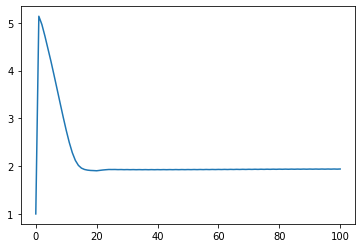

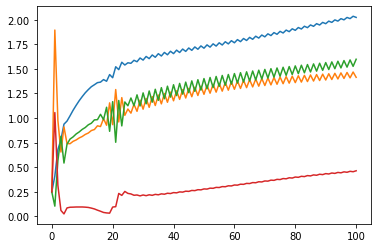

b: 1.939770905698008
w: [-2.02354001 -1.41432533 -1.59818748 -0.46450948]
c: 0.2099644435745744
MLR F1 score: 0.994475138121547
MLR MSE score: 0.006977293701850704


In [177]:
max_iter = 100
l_rate = 1/max_iter
pu_classifier = ModifiedLogisticRegression(max_iter = max_iter, l_rate = l_rate, seed = 331)
name = "MLR"

pu_classifier.fit(np.copy(X1_train), np.copy(s1))

pu_classifier.estimate_c()

y_pred = pu_classifier.predict(np.copy(X1_test))

y_pred_prob = pu_classifier.predict_proba(np.copy(X1_test))
print("b:",pu_classifier.b)
print("w:",pu_classifier.w)
print("c:",pu_classifier.c)
print(name,"F1 score:", f1_score(y1_test, y_pred))
print(name,"MSE score:", mse(y_best_prob, y_pred_prob))

# Second dataset

### https://archive.ics.uci.edu/ml/datasets/Diabetic+Retinopathy+Debrecen+Data+Set

In [178]:
data = pd.read_csv('Dataset2_train.csv')
X2_train= data.iloc[:, :-2].values
y2_train = data.iloc[:, -1].values
s2 = data.iloc[:, -2].values
c2 = Counter(s2)[1]/Counter(y2_train)[1]
print(c2)

data = pd.read_csv('Dataset2_test.csv')
X2_test= data.iloc[:, :-1].values
y2_test = data.iloc[:, -1].values

0.19813519813519814


### Golden Standard Classifier (second dataset)

In [179]:
# Consider the dataset as fully labeled. Use this as the best case in the comparison.

golden_clf = svm.SVC(kernel='rbf',probability=True,random_state = 331).fit(np.copy(X2_train),np.copy(y2_train))
name = "Golden Standard Classifier:"

y_best_pred = golden_clf.predict(np.copy(X2_test))
y_best_prob = golden_clf.predict_proba(np.copy(X2_test))[:,1]

print(name,"F1 score:", f1_score(y2_test, y_best_pred))

Golden Standard Classifier: F1 score: 0.6357615894039735


### Non-Traditional Classifier (second dataset)

In [180]:
#fit a model on (X, s1) and see the performance. Compare it with the two methods.
non_trad_clf = svm.SVC(kernel='rbf', probability=True, random_state = 331).fit(np.copy(X2_train),np.copy(s2))
name = "Non-Traditional Classifier"

y_pred = non_trad_clf.predict(np.copy(X2_test))
y_pred_prob = non_trad_clf.predict_proba(np.copy(X2_test))[:,1]
print(name,"F1 score:", f1_score(y2_test, y_pred))
print(name,"MSE score:", mse(y_best_prob, y_pred_prob))

Non-Traditional Classifier F1 score: 0.0
Non-Traditional Classifier MSE score: 0.21981375019263513


### Spy Expectation Maximization S-EM (second dataset)

In [181]:
pu_classifier = SEM(tol = 1.0e-10, max_iter = 100, spy_prop = 0.1, l = 0.15, 
                    classifier = LogisticRegression(), seed=331)
name = "SEM"

pu_classifier.fit(np.copy(X2_train), np.copy(s2))

y_pred = pu_classifier.predict(np.copy(X2_test))

y_pred_prob = pu_classifier.predict_proba(np.copy(X2_test))[:,1]

print(name,"F1 score:", f1_score(y2_test, y_pred))
print(name,"MSE score:", mse(y_best_prob, y_pred_prob))


Number of iterations first step: 100
P: 85
N: 503
U: 217
Number of iterations second step: 3
SEM F1 score: 0.5993031358885018
SEM MSE score: 0.056869553391350545


### Modified Logistic Regression MLR (second dataset)

Number of iterations: 100


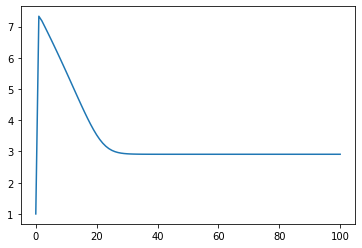

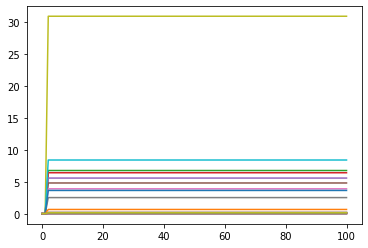

b: 2.9104275004359965
w: [ 0.23994137  0.2324545   6.7876798   6.43758772  5.60805352  4.84122031
  3.93163138  2.55969095 30.87237894  8.42665637  3.67601307  0.70494441
  0.18395914  0.08953226  0.06185071  0.05771231  0.15131651  0.07352598
  0.18890702]
c: 0.10559006211180118
MLR F1 score: 0.6893939393939393
MLR MSE score: 0.2890492909110298


In [182]:
max_iter = 100
l_rate = 1/max_iter
pu_classifier = ModifiedLogisticRegression(max_iter = max_iter, l_rate = l_rate, seed = 331)
name = "MLR"

pu_classifier.fit(np.copy(X2_train), np.copy(s2))

pu_classifier.estimate_c()

y_pred = pu_classifier.predict(np.copy(X2_test))

y_pred_prob = pu_classifier.predict_proba(np.copy(X2_test))

print("b:",pu_classifier.b)
print("w:",pu_classifier.w)
print("c:",pu_classifier.c)
print(name,"F1 score:", f1_score(y2_test, y_pred))
print(name,"MSE score:", mse(y_best_prob, y_pred_prob))

### EXPERIMENTS

### Spy Expectation Maximization S-EM (second dataset) (SCAR + GaussianNB)

In [183]:
pu_classifier = SEM(tol = 1.0e-10, max_iter = 100, spy_prop = 0.1, l = 0.15, 
                    classifier = GaussianNB(), seed=331)
name = "SEM"

pu_classifier.fit(np.copy(X2_train), np.copy(s2))

y_pred = pu_classifier.predict(np.copy(X2_test))

y_pred_prob = pu_classifier.predict_proba(np.copy(X2_test))[:,1]

print(name,"F1 score:", f1_score(y2_test, y_pred))
print(name,"MSE score:", mse(y_best_prob, y_pred_prob))

Number of iterations first step: 49
P: 85
N: 17
U: 703
Number of iterations second step: 1
SEM F1 score: 0.6575342465753424
SEM MSE score: 0.31525103678038374


### Spy Expectation Maximization S-EM (second dataset) (SCAR + GaussianNB)